In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r"..\datasets\clean_dataset.csv")
df.head(5)

,appointment_id,patient_id,age,gender,postcode_area,distance_to_clinic_km,clinic_id,clinic_type,appointment_type,consultation_fee,...,days_since_last_visit,has_chronic_condition_flag,sms_reminder_sent,reminder_hours_before,reminder_response,number_of_reminders_sent,estimated_revenue_loss_gbp,staff_idle_cost_gbp,slot_rebooked_flag,no_show
0,1,861,53,Male,B15,6.2,C1,Physiotherapy,New Patient,93,...,204,0,1,48,Confirmed,1,0,0.00,0,0
1,2,1295,32,Male,CF10,5.9,C3,GP,Follow-up,68,...,123,1,1,24,Confirmed,1,68,23.80,1,1
2,3,1131,18,Male,BS1,3.6,C2,Physiotherapy,Follow-up,104,...,9,0,1,24,Confirmed,1,0,0.00,0,0
3,4,1096,43,Female,M1,7.5,C4,GP,Follow-up,93,...,55,0,1,48,Confirmed,1,93,32.55,0,1
4,5,1639,21,Male,G1,5.5,C5,Dermatology,New Patient,182,...,105,0,0,24,No Reminder,1,182,63.70,1,1


In [3]:
df.columns

Index(['appointment_id', 'patient_id', 'age', 'gender', 'postcode_area',
       'distance_to_clinic_km', 'clinic_id', 'clinic_type', 'appointment_type',
       'consultation_fee', 'appo_book_date', 'appointment_date',
       'appointment_day_of_week', 'appointment_hour', 'appo_wait_days',
       'is_weekend', 'is_peak_hour', 'patient_total_appointments',
       'missed_appointment', 'patient_noshow_rate', 'days_since_last_visit',
       'has_chronic_condition_flag', 'sms_reminder_sent',
       'reminder_hours_before', 'reminder_response',
       'number_of_reminders_sent', 'estimated_revenue_loss_gbp',
       'staff_idle_cost_gbp', 'slot_rebooked_flag', 'no_show'],
      dtype='object')

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
appointment_id,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.00
patient_id,10000.0,1502.626900,865.021722,1.0,762.75,1493.0,2250.25,3000.00
age,10000.0,41.867300,14.178180,18.0,32.00,41.0,51.00,90.00
distance_to_clinic_km,10000.0,6.020870,4.283646,0.5,2.90,5.0,8.20,35.00
consultation_fee,10000.0,103.188400,33.563077,60.0,78.00,92.0,125.00,199.00
appointment_hour,10000.0,12.960800,2.597140,9.0,11.00,13.0,15.00,17.00
appo_wait_days,10000.0,13.530600,8.085258,0.0,7.00,14.0,21.00,27.00
is_weekend,10000.0,0.278800,0.448431,0.0,0.00,0.0,1.00,1.00
is_peak_hour,10000.0,0.326800,0.469067,0.0,0.00,0.0,1.00,1.00
patient_total_appointments,10000.0,1.961400,1.370145,1.0,1.00,1.0,3.00,11.00


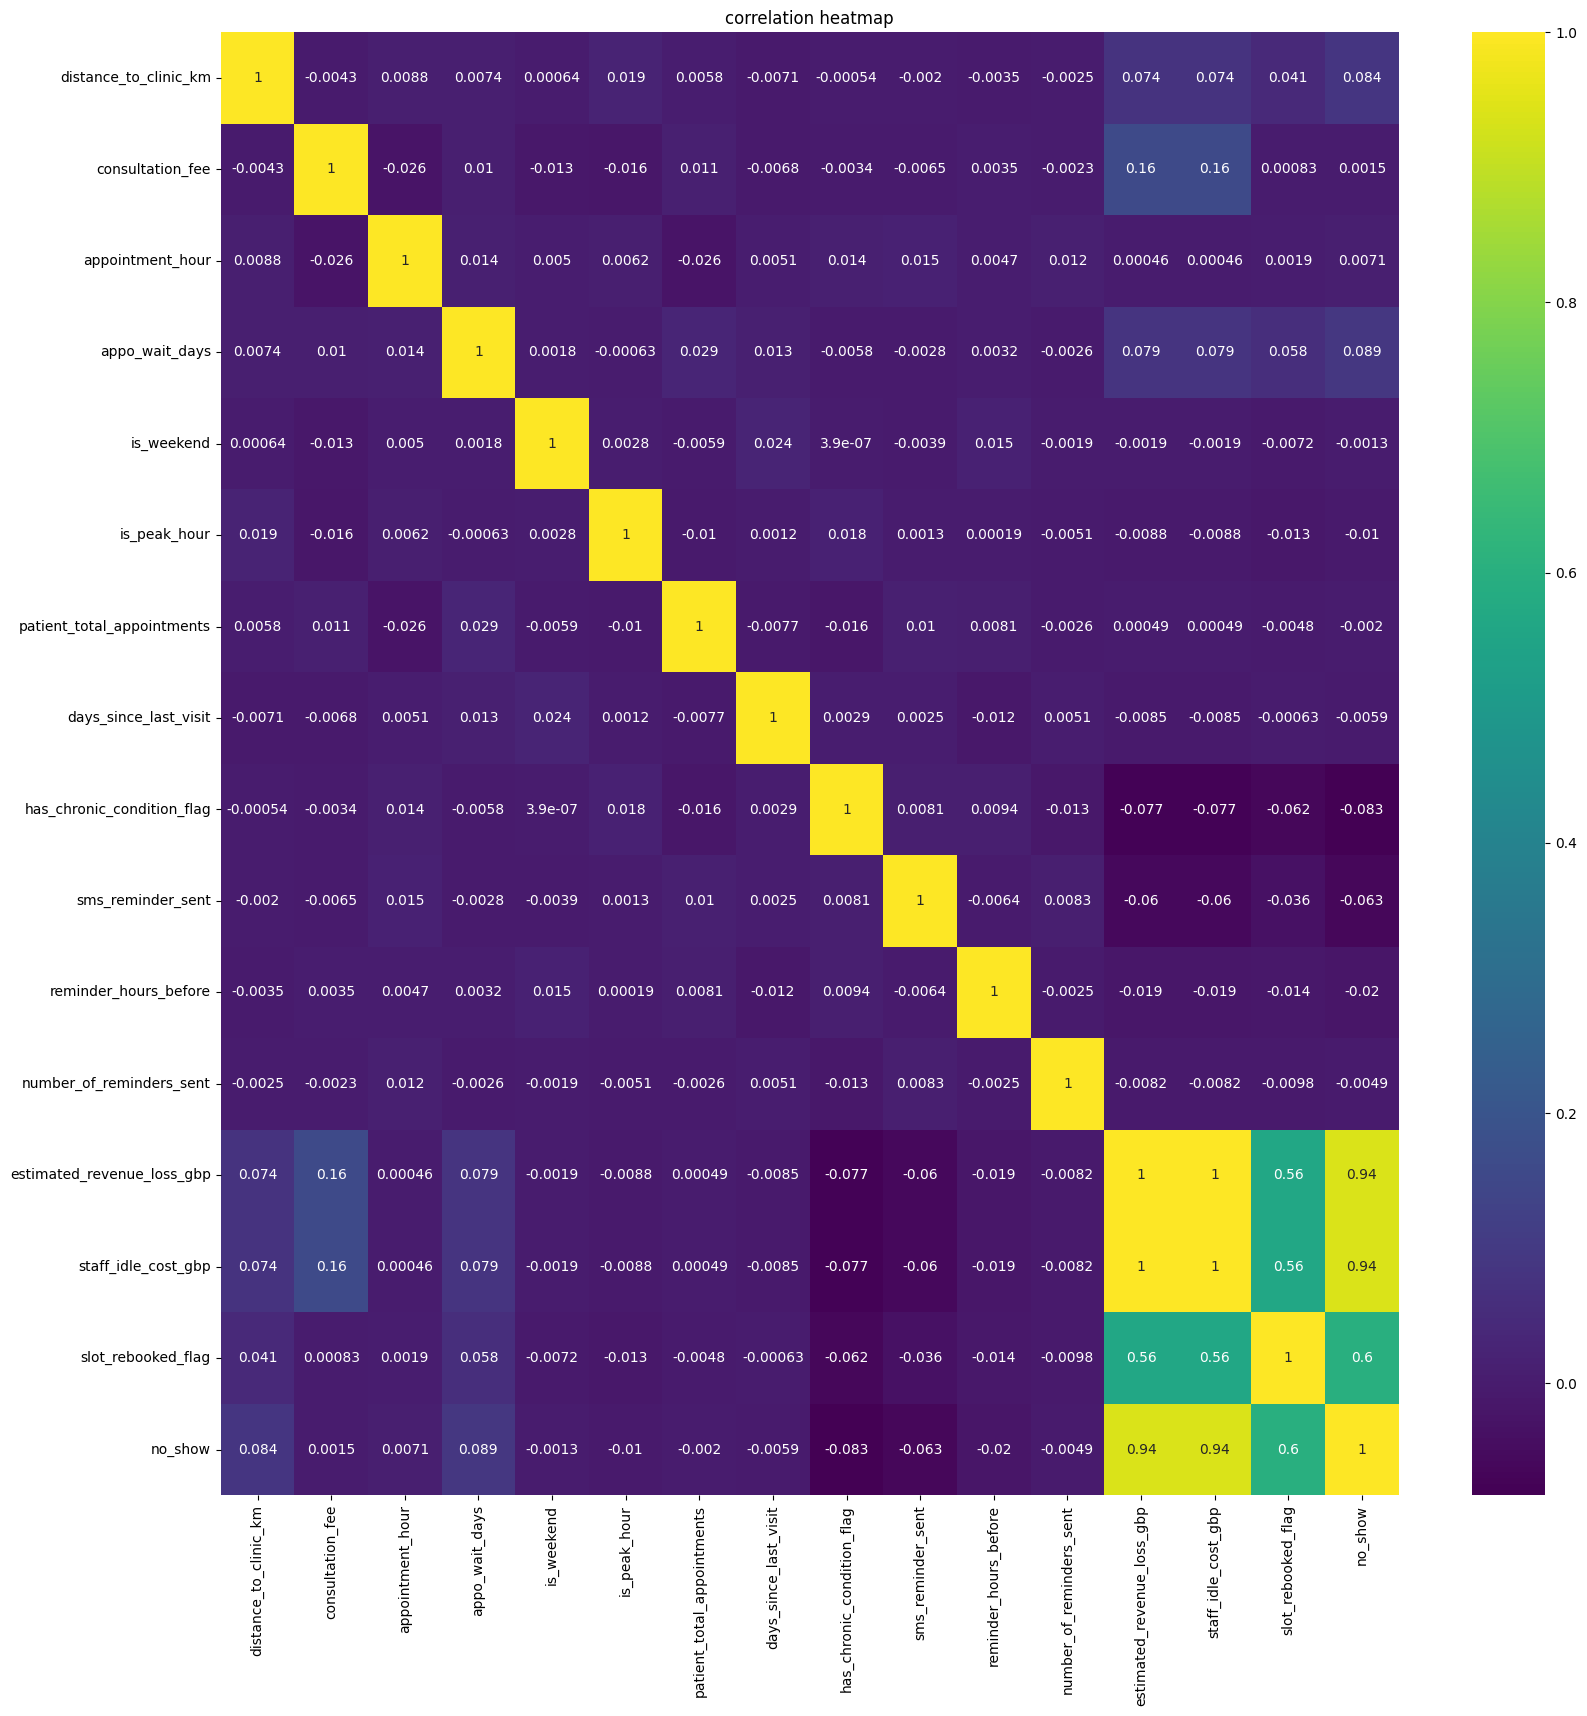

In [5]:
drop_col = df.drop(columns=['appointment_id' , 'patient_id' , 'age' , 'missed_appointment','patient_noshow_rate'])
numeric_cols = drop_col.select_dtypes(include=['int64','float32','int32','float64'])
plt.figure(figsize=(19,19))
sns.heatmap(numeric_cols.corr() , annot=True ,cmap="viridis" )
plt.title("correlation heatmap")
plt.show()

1 . **Strong Leakage Features**

-> estimated_revenue_loss_gbp and staff_idle_cost_gbp show almost perfect correlation with no_show (0.94) and with each other (1.00).

2 . **Moderate Link with Slot Rebooking**

-> slot_rebooked_flag has a correlation of 0.60 with no_show. This makes sense — when a patient does not show up, the clinic tries to rebook the slot. However, this feature is also partly outcome-dependent and should be used carefully.

4 . **Very Weak relationship**

-> Most features (distance, appointment hour, weekend flag, peak hour, total appointments, reminder-related columns) have correlations close to zero with no_show

5 . **Slight Positive Signals**

-> day_gap (days in advance) → +0.089
distance_to_clinic_km → +0.084

* show outliers

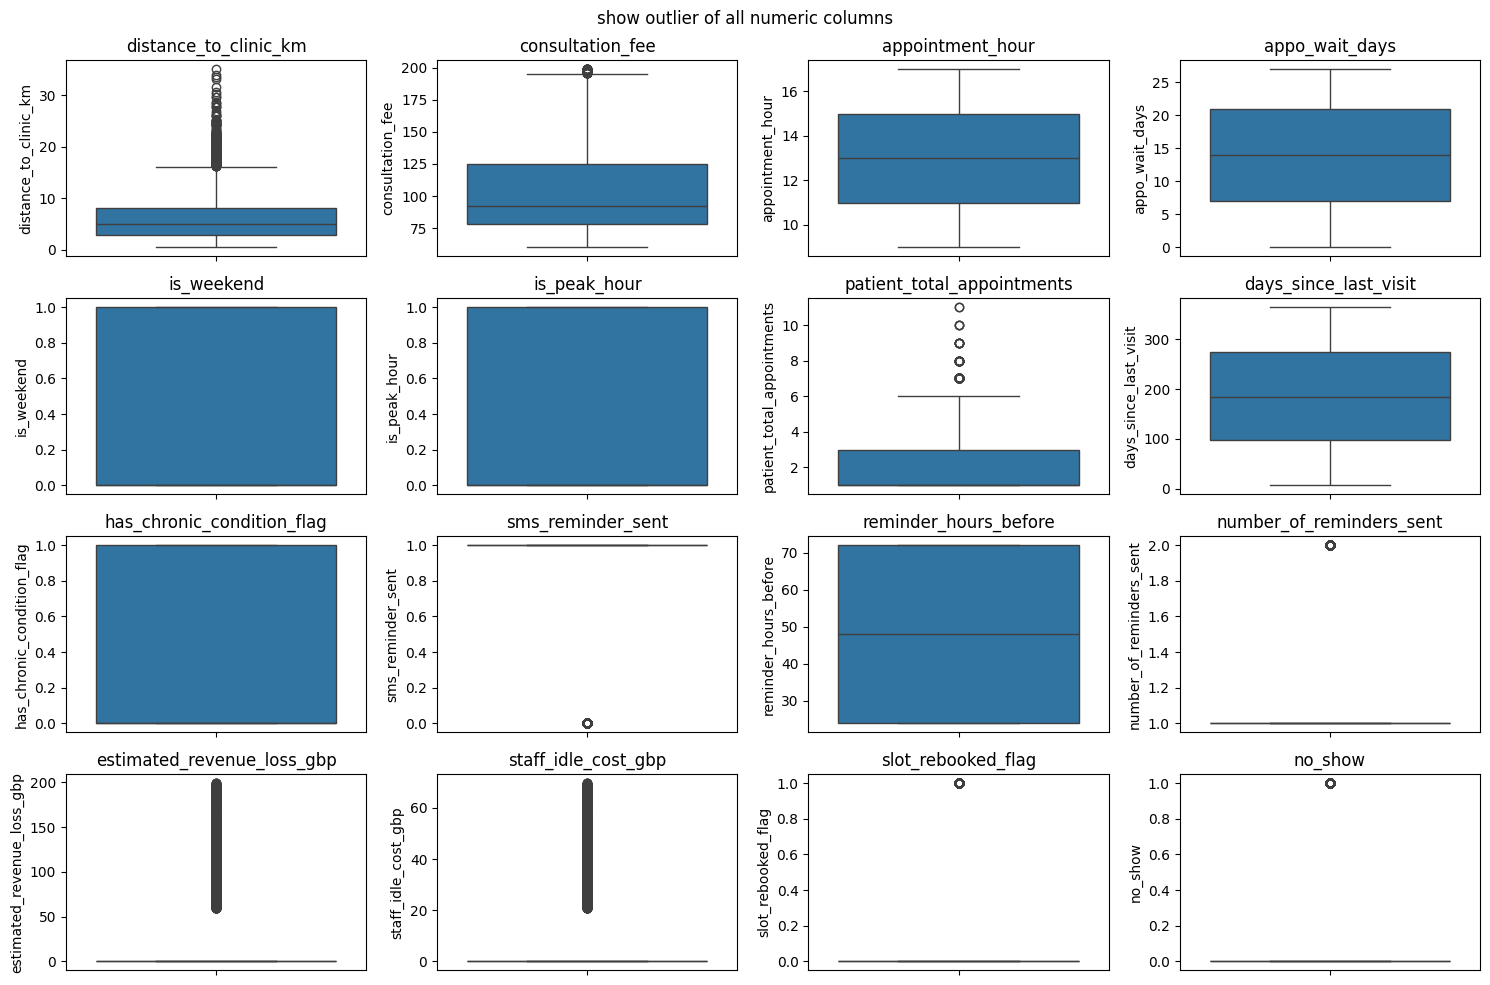

In [6]:
# numerical_cols = df.select_dtypes(include=["float64", "int64"]).columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(4, 4, i + 1) # adjust the number of rows and columns as needed
    sns.boxplot(df[col])
    plt.title(col)
plt.suptitle('show outlier of all numeric columns')
plt.tight_layout()
plt.show()

In [7]:
# how many outlier in column??
def detect_outliers(df , col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_iqr = ((df[col] < lower_bound) | (df[col] > upper_bound))
    print(f"IQR method identified {outliers_iqr.sum()} outliers in {col}")
    return outliers_iqr

outlier_col = ['distance_to_clinic_km' , 'consultation_fee' , 'patient_total_appointments' , 'estimated_revenue_loss_gbp' , 'staff_idle_cost_gbp']

for col in outlier_col:
    detect_outliers(df ,col)

IQR method identified 284 outliers in distance_to_clinic_km
IQR method identified 65 outliers in consultation_fee
IQR method identified 108 outliers in patient_total_appointments
IQR method identified 2143 outliers in estimated_revenue_loss_gbp
IQR method identified 2143 outliers in staff_idle_cost_gbp


# 📊 KPI

In [35]:
avg_appo_wait_days = df['appo_wait_days'].mean()
print(f"Average appointment wait days: {avg_appo_wait_days:.2f}")

total_appointment =df['appointment_id'].count()
print(f"total appointment : {total_appointment}")

total_patient = df['patient_id'].nunique()
print(f"total patient : {total_patient}")

noshow_rate   = df["no_show"].mean() * 100
print(f"no show rate : {noshow_rate:.2f}")

rebook_rate   = df.loc[df["no_show"] == 1, "slot_rebooked_flag"].mean() * 100
print(f"slot rebook rate : {rebook_rate:.2f}")


Average appointment wait days: 13.53
total appointment : 10000
total patient : 2890
no show rate : 21.43
slot rebook rate : 41.53


* analysis

# A . Where is the bottleneck? (wait times)

1 . Which clinic_type have average appointment wait times above the 7-day clinical target

In [18]:
target_days = 7
appo_wait_days = df.groupby('clinic_type').agg(
    avg_wait_days = ('appo_wait_days' , 'mean') , 
    total_appointment = ('appointment_id' , 'count'),
     pct_over_7d   =("appo_wait_days", lambda x: (x > target_days).mean() * 100),
).round(2).sort_values("avg_wait_days", ascending=False)
display(appo_wait_days)

,avg_wait_days,total_appointment,pct_over_7d
clinic_type,,,
Dental,13.68,1995,71.83
Physiotherapy,13.59,1978,71.28
Dermatology,13.50,1486,71.27
GP,13.45,4541,71.20


* The overall average is 13.5 days against a 7-day promise.
* The gap between clinic types is tiny, only 0.23 days
* Since the delay is the same everywhere, the cause is probably systemic not one weak department.

2 . Which clinic_type  have the longest waits, and what share of their patients wait more than 14 days?

In [46]:
clinic_type_analysis = df.groupby('clinic_type').agg(
    avg_wait_days = ('appo_wait_days' , 'mean') ,
    total_appointments = ('appointment_id' , 'count'),
    patients_waiting_over_14_days = ('appo_wait_days', lambda x: (x > 14).sum())).round(2).sort_values(by='avg_wait_days' , ascending=False)

clinic_type_analysis['pct_wait_over_14_days'] = (
    clinic_type_analysis['patients_waiting_over_14_days'] / 
    clinic_type_analysis['total_appointments'] * 100
).round(2)
display(clinic_type_analysis)

,avg_wait_days,total_appointments,patients_waiting_over_14_days,pct_wait_over_14_days
clinic_type,,,,
Dental,13.68,1995,961,48.17
Physiotherapy,13.59,1978,936,47.32
Dermatology,13.50,1486,692,46.57
GP,13.45,4541,2084,45.89


**Dental has the longest average wait** at **13.68 days**, narrowly ahead of Physiotherapy (**13.59 days**). Dental also has the highest share of appointments waiting more than 14 days: **48.17%**—nearly one in two.

The differences across clinic types are modest: average waits span just **0.23 days**, and the over-14-day share ranges from **45.89% to 48.17%**. 

Still, all four clinic types have a substantial proportion of appointments exceeding the 14-day mark, suggesting long waits are not limited to one service.


**3 . Is the wait getting worse over time (monthly trend of appo_wait_days)?**

Monthly Average Wait Days Trend:


,year_month,avg_wait_days,total_appointments
0,2026-01,9.57,485
1,2026-02,13.26,736
2,2026-03,13.35,860
3,2026-04,13.76,800
4,2026-05,13.29,831
5,2026-06,13.59,799
6,2026-07,13.70,901
7,2026-08,13.92,886
8,2026-09,13.56,816
9,2026-10,13.37,830


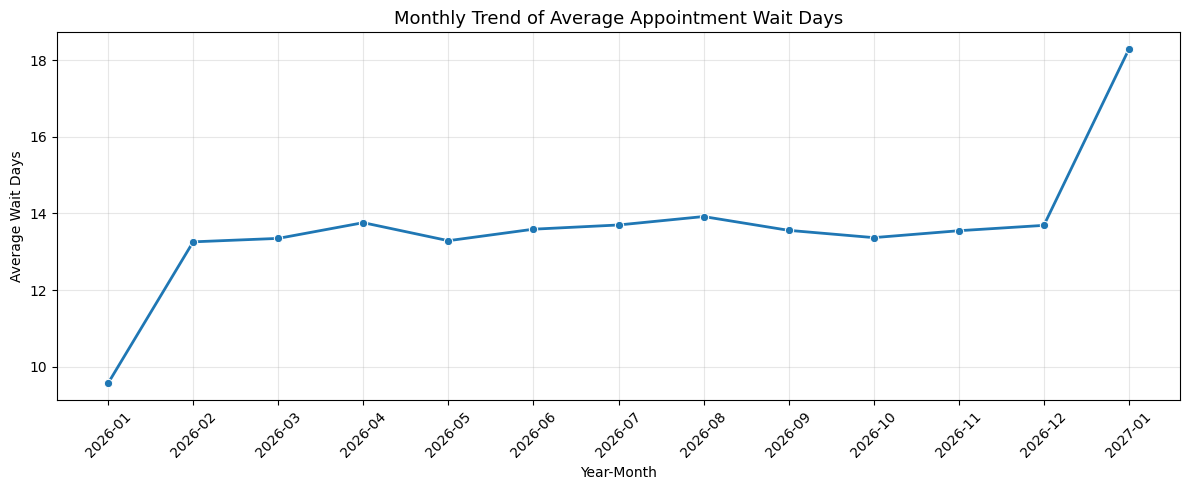

In [6]:
# Ensure datetime columns are in correct format
df['appointment_date'] = pd.to_datetime(df['appointment_date'])

# Create Year)-Month column
df['year_month'] = df['appointment_date'].dt.to_period('M')

# Calculate monthly average wait days
monthly_trend = df.groupby('year_month').agg(
    avg_wait_days = ('appo_wait_days', 'mean'),
    total_appointments = ('appointment_id', 'count')
).round(2).reset_index()

# Convert period to string for plotting
monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

# Display the trend table
print("Monthly Average Wait Days Trend:")
display(monthly_trend)

# Plot the trend
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='year_month', y='avg_wait_days', marker='o', linewidth=2)
plt.title("Monthly Trend of Average Appointment Wait Days", fontsize=13)
plt.xlabel("Year-Month")
plt.ylabel("Average Wait Days")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

* Wait times increased overall: The average rose from 9.57 days in January 2026 to around 13–14 days for most of February–December, suggesting a higher typical wait after January.

* The trend was mostly stable, with a late spike: Waits fluctuated slightly through 2026, then reached 18.29 days in January 2027. 

**4 . Which patient groups wait longest (new vs follow-up, chronic condition, age group, distance to clinic)?**

In [48]:
from scipy.stats import f_oneway
TARGET = 7

# ---------- Build groups ----------
df["age_group"] = pd.cut(df["age"], [0, 17, 34, 49, 64, 120],
                         labels=["<18", "18-34", "35-49", "50-64", "65+"])
df["distance_group"] = pd.cut(df["distance_to_clinic_km"], [-1, 2, 5, 10, 20, 1000],
                              labels=["0-2 km", "2-5 km", "5-10 km", "10-20 km", "20+ km"])
df["chronic"] = df["has_chronic_condition_flag"].map({0: "No chronic condition", 1: "Chronic condition"})

# ---------- Wait summary + significance for each group ----------
def wait_by(col):
    g = df.groupby(col, observed=True)["appo_wait_days"]
    out = pd.DataFrame({
        "patients":  g.size(),
        "avg_wait":  g.mean(),
        "median":    g.median(),
        "p90":       g.quantile(0.90),
        "pct_over_7d": g.apply(lambda x: (x > TARGET).mean() * 100),
    }).round(2)
    p = f_oneway(*[x["appo_wait_days"] for _, x in df.groupby(col, observed=True)])[1]
    print(f"\n=== {col} (p = {p:.3f}, {'REAL difference' if p < 0.05 else 'no real difference'}) ===")
    display(out)

for c in ["appointment_type", "chronic", "age_group", "distance_group"]:
    wait_by(c)

# ---------- Does any numeric factor drive wait? ----------
print("\nCorrelation with wait days:")
print(df[["appo_wait_days", "age", "distance_to_clinic_km",
          "patient_total_appointments", "days_since_last_visit"]]
      .corr()["appo_wait_days"].round(3))


=== appointment_type (p = 0.963, no real difference) ===


,patients,avg_wait,median,p90,pct_over_7d
appointment_type,,,,,
Follow-up,6479,13.53,14.0,25.0,71.11
New Patient,3521,13.54,14.0,25.0,71.80



=== chronic (p = 0.561, no real difference) ===


,patients,avg_wait,median,p90,pct_over_7d
chronic,,,,,
Chronic condition,2934,13.46,13.0,25.0,70.52
No chronic condition,7066,13.56,14.0,25.0,71.70



=== age_group (p = 0.353, no real difference) ===


,patients,avg_wait,median,p90,pct_over_7d
age_group,,,,,
18-34,3172,13.71,14.0,25.0,71.75
35-49,3893,13.43,13.0,25.0,70.95
50-64,2308,13.54,13.0,25.0,71.75
65+,627,13.20,14.0,24.0,70.33



=== distance_group (p = 0.058, no real difference) ===


,patients,avg_wait,median,p90,pct_over_7d
distance_group,,,,,
0-2 km,1508,13.55,14.0,25.0,71.29
2-5 km,3500,13.51,14.0,25.0,71.66
5-10 km,3448,13.52,13.0,25.0,71.11
10-20 km,1438,13.42,13.0,25.0,70.79
20+ km,106,15.86,18.0,25.0,77.36



Correlation with wait days:
appo_wait_days                1.000
age                          -0.012
distance_to_clinic_km         0.007
patient_total_appointments    0.029
days_since_last_visit         0.013
Name: appo_wait_days, dtype: float64


* No patient group waits meaningfully longer. New vs follow-up, chronic vs not, every age band and gender all sit between 13.2 and 13.7 days.

* Only one group stands out: patients living 20+ km away (15.9 days, 2.3 days above average)

# B. Demand vs capacity (volume)

5 . What is the daily and weekly appointment throughput by clinic type?

In [56]:
dept = "clinic_type"   # GP, Dental, Dermatology, Physiotherapy

# ---------- DAILY throughput ----------
daily = (df.groupby([dept, "appointment_date"]).size()
           .rename("appointments").reset_index())

# keep only complete weeks (first/last weeks are partial and pull averages down)
df["week_start"] = df["appointment_date"].dt.to_period("W").dt.start_time
weekly = (df.groupby([dept, "week_start"]).size()
            .rename("appointments").reset_index())

first_full = df["week_start"].min() + pd.Timedelta(weeks=1)
last_full  = df["week_start"].max() - pd.Timedelta(weeks=1)
weekly_full = weekly[weekly["week_start"].between(first_full, last_full)]
daily_full  = daily[daily["appointment_date"].between(first_full, last_full + pd.Timedelta(days=6))]

def summarize(data):
    s = data.groupby(dept)["appointments"].agg(["mean"]).round(1)
    return s

daily_summary  = summarize(daily_full)
weekly_summary = summarize(weekly_full)
weekly_summary["share_pct"] = (weekly_summary["mean"] / weekly_summary["mean"].sum() * 100).round(1)

print("DAILY appointment per department")
display(daily_summary.sort_values(by='mean' , ascending=False))
print("WEEKLY appointment per department")
display(weekly_summary.sort_values(by='mean' , ascending=False))

# ---------- Day-of-week pattern ----------
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = (daily_full.assign(dow=daily_full["appointment_date"].dt.day_name())
         .groupby([dept, "dow"])["appointments"].mean().round(1)
         .unstack()[order])
print("Avg daily appointments by weekday")
display(dow)


DAILY appointment per department


,mean
clinic_type,
GP,11.8
Dental,5.3
Physiotherapy,5.2
Dermatology,4.0


WEEKLY appointment per department


,mean,share_pct
clinic_type,,
GP,82.5,45.5
Dental,36.2,19.9
Physiotherapy,35.9,19.8
Dermatology,26.9,14.8


Avg daily appointments by weekday


dow,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
clinic_type,,,,,,,
Dental,5.5,5.0,5.1,5.3,5.5,5.2,5.1
Dermatology,4.3,4.2,3.9,3.9,3.9,3.8,3.9
GP,11.7,11.5,12.1,11.8,11.9,12.0,11.8
Physiotherapy,5.1,5.4,4.9,6.0,5.5,5.1,4.7


* GP carries almost half the load. It sees about 12 patients a day, more than Dental and Physio combined.

* Dermatology is the smallest at about 4 a day. Combined with Q1 (all departments wait about 13.5 days),

**6 . Which time slots (hour) and days of the week are busiest, and where is the load unevenly spread?**

In [22]:
hour_appointment = df.groupby('appointment_hour').agg(
    total_appointment = ('appointment_id' , 'count') , 
).sort_values(by='appointment_hour').round(0)

print("=====businest hour=======")
display(hour_appointment)

# 2. Busiest Days of the Week
day_analysis = df.groupby('appointment_day_of_week').agg(
    total_appointments = ('appointment_id', 'count')
).sort_values(by='total_appointments', ascending=False)

print("\n=== Busiest Days of the Week ===")
display(day_analysis)

# 3. Combined view (Hour + Day) to see uneven load
hour_day_analysis = df.groupby(['appointment_day_of_week', 'appointment_hour']).agg(
    total_appointments = ('appointment_id', 'count')
).reset_index()
top_busy_slots = hour_day_analysis.sort_values(by='total_appointments', ascending=False).head(10)
print("\n=== Top 10 Busiest Day + Hour Combinations ===")
display(top_busy_slots)

=====businest hour=======


,total_appointment
appointment_hour,
9,1150
10,1140
11,1133
12,1106
13,1109
14,1053
15,1094
16,1101
17,1114



=== Busiest Days of the Week ===


,total_appointments
appointment_day_of_week,
Friday,1470
Monday,1463
Thursday,1456
Tuesday,1424
Saturday,1405
Wednesday,1399
Sunday,1383



=== Top 10 Busiest Day + Hour Combinations ===


,appointment_day_of_week,appointment_hour,total_appointments
9,Monday,9,177
40,Thursday,13,177
46,Tuesday,10,177
47,Tuesday,11,176
56,Wednesday,11,176
7,Friday,16,175
0,Friday,9,174
10,Monday,10,174
44,Thursday,17,173
54,Wednesday,9,173


* Busiest hours are fairly consistent: Appointment volume is highest at 9:00 AM (1,150 appointments) and lowest at 2:00 PM (1,053). so hourly demand is relatively evenly distributed accros the day

* Days are also balanced, with a few peak slots: Friday has the most appointments (1,470), while Sunday has the fewest (1,383). The busiest day-hour combinations are Monday at 9:00 AM, Thursday at 1:00 PM, and Tuesday at 10:00 AM (177 appointments each),

7 . Which department-clinic combinations carry a high share of volume but have long waits, and which have low volume and short waits? (this answers “who can absorb more”)

In [26]:
# Department + Clinic combination analysis
# Goal: Identify which combinations are overloaded vs which can absorb more demand

combo_analysis = df.groupby(['clinic_type']).agg(
    total_appointments = ('appointment_id', 'count'),
    avg_wait_days = ('appo_wait_days', 'mean')
).round(2).reset_index()

# Calculate volume share (%)
combo_analysis['volume_share_pct'] = (
    combo_analysis['total_appointments'] / combo_analysis['total_appointments'].sum() * 100
).round(2)

# Create categories to answer the question
def categorize(row):
    high_volume = row['volume_share_pct'] >= combo_analysis['volume_share_pct'].median()
    long_wait = row['avg_wait_days'] >= combo_analysis['avg_wait_days'].median()
    
    if high_volume and long_wait:
        return 'High Volume + Long Wait (Overloaded)'
    elif high_volume and not long_wait:
        return 'High Volume + Short Wait'
    elif not high_volume and long_wait:
        return 'Low Volume + Long Wait'
    else:
        return 'Low Volume + Short Wait (Can Absorb More)'

combo_analysis['category'] = combo_analysis.apply(categorize, axis=1)

# Sort for better readability
combo_analysis = combo_analysis.sort_values(
    by=['category', 'volume_share_pct'], 
    ascending=[True, False]
)

display(combo_analysis)

,clinic_type,total_appointments,avg_wait_days,volume_share_pct,category
0,Dental,1995,13.68,19.95,High Volume + Long Wait (Overloaded)
2,GP,4541,13.45,45.41,High Volume + Short Wait
3,Physiotherapy,1978,13.59,19.78,Low Volume + Long Wait
1,Dermatology,1486,13.50,14.86,Low Volume + Short Wait (Can Absorb More)


* Dental has a relatively high volume share (19.95%) and the longest average wait (13.68 days).

* Dermatology has the lowest volume share (14.86%) and a shorter average wait (13.50 days),

* d. GP handles the largest share (45.41%) with the shortest wait (13.45 days)

# C. Capacity lost to waste (hidden capacity)

8 . Which time slots, days and departments have the highest no-show rates?

In [32]:
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

def rates(col, order=None):
    r = df.groupby(col).agg(
        appointments=("no_show", "size"),
        noshow_pct=("no_show", lambda x: x.mean() * 100),
    ).round(1)
    return r.reindex(order) if order else r

by_hour = rates("appointment_hour")
by_day  = rates("appointment_day_of_week", days)
by_clinic_type = rates("clinic_type")

print("Overall no-show:", round(df["no_show"].mean()*100,1), "% ")
print("======BY HOUR=====")
display(by_hour.sort_values("noshow_pct", ascending=False))
print("==========BY DAY========")
display(by_day.sort_values("noshow_pct", ascending=False))
print("==========BY CLINIC TYPE========")
display(by_clinic_type.sort_values("noshow_pct", ascending=False))


Overall no-show: 21.4 % 
======BY HOUR=====


,appointments,noshow_pct
appointment_hour,,
17,1114,23.9
10,1140,22.5
9,1150,22.2
14,1053,22.1
16,1101,21.5
15,1094,20.4
13,1109,20.3
12,1106,20.2
11,1133,19.8


==========BY DAY========


,appointments,noshow_pct
appointment_day_of_week,,
Tuesday,1424,22.9
Monday,1463,22.4
Saturday,1405,21.9
Sunday,1383,20.8
Wednesday,1399,20.7
Friday,1470,20.7
Thursday,1456,20.7


==========BY CLINIC TYPE========


,appointments,noshow_pct
clinic_type,,
Physiotherapy,1978,21.8
Dental,1995,21.7
GP,4541,21.6
Dermatology,1486,20.1


* Highest-risk times and days: The highest no-show rate occurs at 5:00 PM (23.9%), followed by 10:00 AM (22.5%). Tuesday has the highest rate by day (22.9%), with Monday close behind (22.4%).

* Clinic rates are similar: Physiotherapy has the highest clinic no-show rate (21.8%), closely followed by Dental (21.7%) and GP (21.6%). Dermatology has the lowest rate (20.1%). Overall, 21.4% of appointments were missed.

9 . How much capacity is lost to no-shows, and how many of those slots were re-booked (slot_rebooked_flag)?

In [33]:
# Total no-shows
total_noshows = df[df['no_show'] == 1].shape[0]

# No-shows that were successfully re-booked
rebooked_noshows = df[(df['no_show'] == 1) & (df['slot_rebooked_flag'] == 1)].shape[0]

# No-shows that remained empty (true capacity loss)
lost_slots = df[(df['no_show'] == 1) & (df['slot_rebooked_flag'] == 0)].shape[0]

# Summary
print("=" * 60)
print("CAPACITY LOST TO NO-SHOWS")
print("=" * 60)
print(f"Total No-Shows                : {total_noshows:,}")
print(f"Re-booked Slots               : {rebooked_noshows:,}")
print(f"Truly Lost Slots (not rebooked): {lost_slots:,}")
print("-" * 60)
print(f"% of No-Shows Re-booked       : {rebooked_noshows / total_noshows * 100:.2f}%")
print(f"% of No-Shows Truly Lost      : {lost_slots / total_noshows * 100:.2f}%")
print("=" * 60)

CAPACITY LOST TO NO-SHOWS
Total No-Shows                : 2,143
Re-booked Slots               : 890
Truly Lost Slots (not rebooked): 1,253
------------------------------------------------------------
% of No-Shows Re-booked       : 41.53%
% of No-Shows Truly Lost      : 58.47%


10 . Do reminders (SMS sent, response, hours before, number sent) reduce no-shows?

In [ ]:
# Do reminders reduce no-shows?
print("=" * 65)
print("1. Impact of SMS Reminder Sent")
print("=" * 65)
sms_impact = df.groupby('sms_reminder_sent')['no_show'].agg(['count', 'mean']).round(4)
sms_impact.columns = ['total_appointments', 'no_show_rate']
sms_impact['no_show_rate_%'] = (sms_impact['no_show_rate'] * 100).round(2)
display(sms_impact)

print("\n" + "=" * 65)
print("2. Impact of Reminder Response")
print("=" * 65)
response_impact = df.groupby('reminder_response')['no_show'].agg(['count', 'mean']).round(4)
response_impact.columns = ['total_appointments', 'no_show_rate']
response_impact['no_show_rate_%'] = (response_impact['no_show_rate'] * 100).round(2)
response_impact = response_impact.sort_values('no_show_rate')
display(response_impact)

print("\n" + "=" * 65)
print("3. Impact of Reminder Hours Before Appointment")
print("=" * 65)
hours_impact = df.groupby('reminder_hours_before')['no_show'].agg(['count', 'mean']).round(4)
hours_impact.columns = ['total_appointments', 'no_show_rate']
hours_impact['no_show_rate_%'] = (hours_impact['no_show_rate'] * 100).round(2)
display(hours_impact)

print("\n" + "=" * 65)
print("4. Impact of Number of Reminders Sent")
print("=" * 65)
num_impact = df.groupby('number_of_reminders_sent')['no_show'].agg(['count', 'mean']).round(4)
num_impact.columns = ['total_appointments', 'no_show_rate']
num_impact['no_show_rate_%'] = (num_impact['no_show_rate'] * 100).round(2)
display(num_impact)

1. Impact of SMS Reminder Sent


,total_appointments,no_show_rate,no_show_rate_%
sms_reminder_sent,,,
0,1969,0.2661,26.61
1,8031,0.2016,20.16



2. Impact of Reminder Response


,total_appointments,no_show_rate,no_show_rate_%
reminder_response,,,
Confirmed,5146,0.1656,16.56
Ignored,2050,0.2532,25.32
No Reminder,1969,0.2661,26.61
Cancelled,835,0.2970,29.70



3. Impact of Reminder Hours Before Appointment


,total_appointments,no_show_rate,no_show_rate_%
reminder_hours_before,,,
24,3322,0.2200,22.00
48,3349,0.2225,22.25
72,3329,0.2004,20.04



4. Impact of Number of Reminders Sent


,total_appointments,no_show_rate,no_show_rate_%
number_of_reminders_sent,,,
1,7505,0.2155,21.55
2,2495,0.2108,21.08


* SMS reminders clearly help reduce no-shows. Patients who received an SMS had a lower no-show rate (20.2%) compared to those who did not receive any reminder (26.6%).

* Timing and frequency show limited additional benefit. Sending the reminder 72 hours before the appointment performed slightly better than 24 or 48 hours.